
##### COE512
##### Hands-On Assignment 2

# Object Detection with YOLO26
---

Team:

Name1, ID1

Name2, ID2

Name3, ID3

---

Courtesy: This file has been adapted from tutorials by Roboflow



## Setup

### GPU Check

Use `nvidia-smi` command to check for the GPU.
If needed, change colab runtime type and select a GPU runtime.

In [1]:
!nvidia-smi

Thu Oct 15 21:43:07 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 590.48.01              Driver Version: 590.48.01      CUDA Version: 13.1     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5050 ...    Off |   00000000:01:00.0 Off |                  N/A |
| N/A   49C    P8              2W /   55W |    1945MiB /   8151MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

**NOTE:** To make it easier for us to manage directory paths for datasets, images and models we make a `HOME` constant.

In [2]:
import os
# HOME = os.getcwd()
# Change later on during colab runtime.
HOME  = r"/home/areeb/Documents/KFUPM/COE\ 512/Ass2"
print(HOME)

/home/areeb/Documents/KFUPM/COE\ 512/Ass2


### Install required dependencies for YOLO26

In [3]:
%pip install --no-cache-dir "ultralytics>=8.4.0" supervision

Note: you may need to restart the kernel to use updated packages.


In [4]:
# %pip install  "ultralytics>=8.4.0" supervision


!yolo settings sync=False # this is to disable ultralytics tracking your activity
import ultralytics
ultralytics.checks()

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
Setup complete ✅ (24 CPUs, 15.2 GB RAM, 313.4/316.9 GB disk)


### Download example data

Downloads example images for testing. You can use these or replace them with your own images.

In [5]:
!wget -O road1.jpg "https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D"

--2026-10-15 21:43:12--  https://images.unsplash.com/photo-1533826418470-0cef7eb8bdaa?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=M3wxMjA3fDB8MHxwaG90by1wYWdlfHx8fGVufDB8fHx8fA%3D%3D
Resolving images.unsplash.com (images.unsplash.com)... 2a04:4e42:80::720, 199.232.170.208
Connecting to images.unsplash.com (images.unsplash.com)|2a04:4e42:80::720|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2554587 (2.4M) [image/jpeg]
Saving to: ‘road1.jpg’

road1.jpg           100%[===================>]   2.44M  1.02MB/s    in 2.4s    

2026-10-15 21:43:15 (1.02 MB/s) - ‘road1.jpg’ saved [2554587/2554587]



## Inference with Pre-Trained YOLO26n (pre-trained on COCO dataset)

### CLI

**NOTE:** CLI requires no customization or Python code. You can simply run all tasks from the terminal with the yolo command.

In [6]:
!yolo task=detect mode=predict model=yolo26n.pt source={HOME}/road1.jpg save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 120 layers, 2,408,932 parameters, 0 gradients, 5.5 GFLOPs
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/predict
💡 Learn more at https://docs.ultralytics.com/modes/predict


**NOTE:** Result annotated image got saved in `{HOME}/runs/detect/predict/`. Let's display it.

In [7]:
!ls -la {HOME}/runs/detect/predict/

total 4664
drwxrwxr-x 2 areeb areeb    4096 Oct 15 21:43 .
drwxrwxr-x 3 areeb areeb    4096 Oct 15 21:43 ..
-rw-rw-r-- 1 areeb areeb 4765151 Oct 15 21:43 road1.jpg


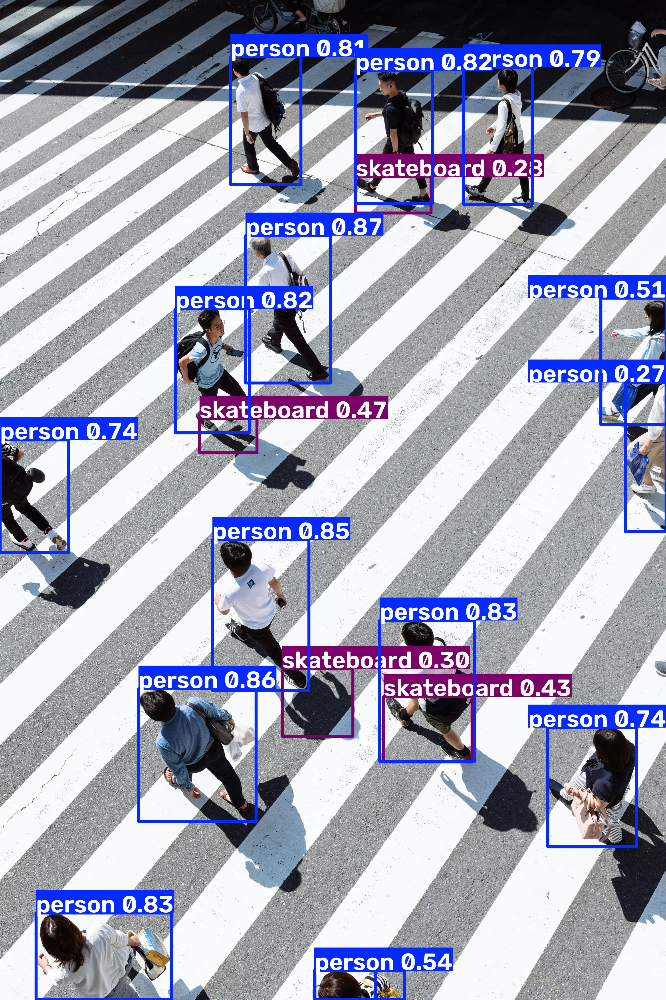

In [8]:
from IPython.display import Image as IPyImage

# IPyImage(filename=f'{HOME}/runs/detect/predict/road1.jpg', width=600)
IPyImage(filename=os.path.join(r"runs/detect/predict/road1.jpg"), width=600)

### SDK

In [9]:
from ultralytics import YOLO
from PIL import Image

model = YOLO('yolo26n.pt')
image = Image.open(f'./road1.jpg')
result = model.predict(image, verbose=False)[0]

**NOTE:** The obtained `result` object stores information about the location, classes, and confidence levels of the detected objects.

The next few cells give a peek into what it contains

In [10]:
result.boxes.xyxy

tensor([[1106.7823, 1059.5642, 1488.6237, 1723.2238],
        [ 624.3823, 3098.5535, 1153.5232, 3696.4062],
        [ 957.4806, 2428.1416, 1391.9092, 3107.8005],
        [ 162.8444, 4108.6152,  773.0254, 4497.8506],
        [1710.9343, 2791.7776, 2138.4680, 3426.6614],
        [1599.9779,  317.9799, 1948.9375,  915.0719],
        [ 790.1225, 1389.9679, 1123.4557, 1946.9399],
        [1038.6735,  255.5562, 1355.6565,  830.3918],
        [2087.4739,  302.5024, 2397.5979,  919.3539],
        [   0.0000, 1979.7136,  309.1217, 2488.0020],
        [2467.5027, 3273.1426, 2867.4573, 3810.6924],
        [1418.6896, 4367.1602, 1821.0255, 4497.8433],
        [2705.0193, 1341.7650, 3000.0000, 1911.0035],
        [ 899.3138, 1883.4468, 1157.5388, 2037.1750],
        [1728.1769, 3135.9250, 2126.0715, 3428.7561],
        [1273.5620, 3008.5078, 1588.3293, 3308.2725],
        [1416.6664, 4366.8174, 1693.0005, 4498.1631],
        [2816.8774, 1719.1514, 3000.0000, 2392.2561],
        [1602.1339,  796.741

In [11]:
result.boxes.conf

tensor([0.8665, 0.8571, 0.8534, 0.8364, 0.8336, 0.8182, 0.8158, 0.8084, 0.7851, 0.7469, 0.7456, 0.5443, 0.5184, 0.4652, 0.4270, 0.3119, 0.2802, 0.2794, 0.2711], device='cuda:0')

In [12]:
result.boxes.cls

tensor([ 0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 36., 36., 36.,  0.,  0., 36.], device='cuda:0')

**NOTE:** YOLO26 can be easily integrated with `supervision` using the familiar `from_ultralytics` connector. `supervision` is a useful library (by Roboflow) for post-inference processing, visualization, etc.

In [13]:
import supervision as sv

detections = sv.Detections.from_ultralytics(result)

In [14]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator()
    label_annotator = sv.LabelAnnotator(
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

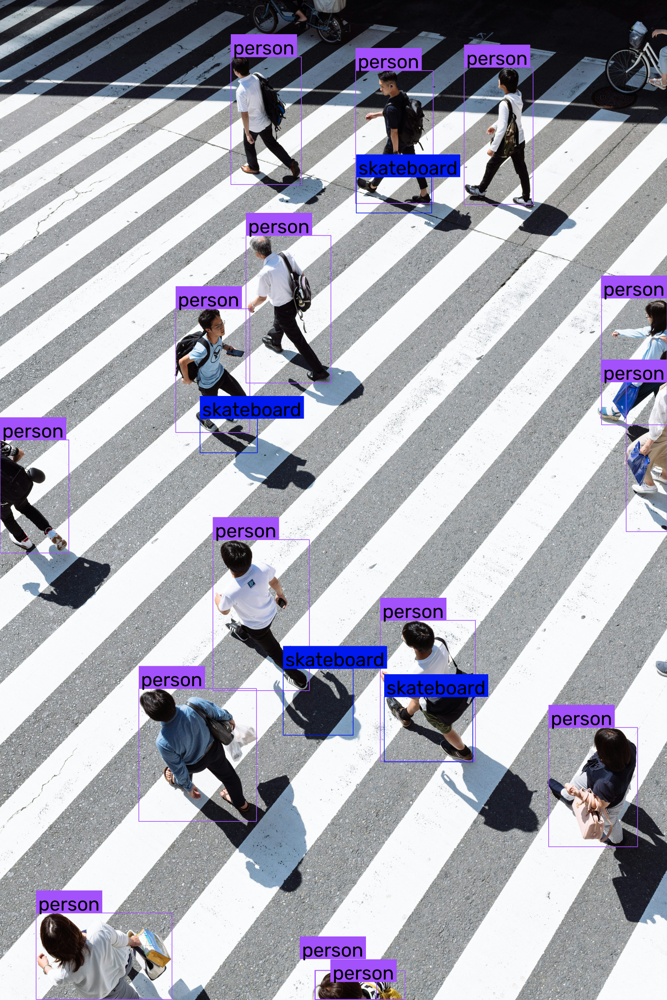

In [15]:
annotated_image = annotate(image, detections)
annotated_image

## Fine-Tuning YOLO26 on PPE Detection Dataset

**NOTE:** make sure your data is located in a directory named
`datasets`.

Running this cell may prompt you asking the following:

> replace /content/datasets/PPEDataset/data.yaml?

Just type `y` if it asks so




In [16]:
# Download the PPEDataset.zip to your colab /content
# Then extract it to /content/datasets/PPEDataset
if os.path.exists(f"{HOME}/datasets/PPEDataset"): 
    print("PPEDataset already exists. Skipping extraction.")
else:
    !mkdir {HOME}/datasets
    !unzip -n PPEDataset.zip -d datasets/PPEDataset

# %cd {HOME}/datasets

Archive:  PPEDataset.zip
 extracting: datasets/PPEDataset/test/images/202234-7-_jpg.rf.76126ad26c1fda6bdf4cfa6d94d7bda5.jpg  
 extracting: datasets/PPEDataset/test/images/img17_png_jpg.rf.c4b231d07e3a84b1707728edfb8dc9fb.jpg  
 extracting: datasets/PPEDataset/train/images/20220721_162848_jpg.rf.002f4ae1f6d94f2e897a5cddccd37f88.jpg  
 extracting: datasets/PPEDataset/train/images/image_173_jpg.rf.044fa1db70739c360666857c253a1fa5.jpg  
 extracting: datasets/PPEDataset/train/images/Video4_49_jpg.rf.0b5332039bfec7da4acdc88b075c3055.jpg  
 extracting: datasets/PPEDataset/train/images/Video2_84_jpg.rf.078a0ba9af0b539a9ea6c0c48b3ffb6f.jpg  
 extracting: datasets/PPEDataset/test/images/ppe_0249_jpg.rf.5d44a6dcf2906e102eaf795eacec41cc.jpg  
 extracting: datasets/PPEDataset/test/images/Screenshot-2024-09-24-132620_png.rf.77ad4a1081ccf23ae70dd2a393c48517.jpg  
 extracting: datasets/PPEDataset/train/images/image_242-1-_jpg.rf.0280a597c86245e9bc0d2a3bc42f518b.jpg  
 extracting: datasets/PPEDataset/t

## Train your Customized YOLO26n

Train for atleast 10 epochs

In [17]:
# %cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=10 imgsz=640 plots=True seed=2026 deterministic=True close_mosaic=10 lrf=1.0

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/areeb/Documents/KFUPM/COE 512/Ass2/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=1.0, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

**NOTE:** The results of the completed training are saved in `{HOME}/runs/detect/train/`. Let's examine them.

If you run the training code cell multiple times, it will make separate folders for each training session. For example `{HOME}/runs/detect/train-2/`, `{HOME}/runs/detect/train-3/` and so on, so modify the directory paths later on as needed

In [18]:
!ls {HOME}/runs/detect/train/

args.yaml			 confusion_matrix.png  train_batch2.jpg
BoxF1_curve.png			 labels.jpg	       val_batch0_labels.jpg
BoxP_curve.png			 results.csv	       val_batch0_pred.jpg
BoxPR_curve.png			 results.png	       weights
BoxR_curve.png			 train_batch0.jpg
confusion_matrix_normalized.png  train_batch1.jpg


### Confusion Matrix

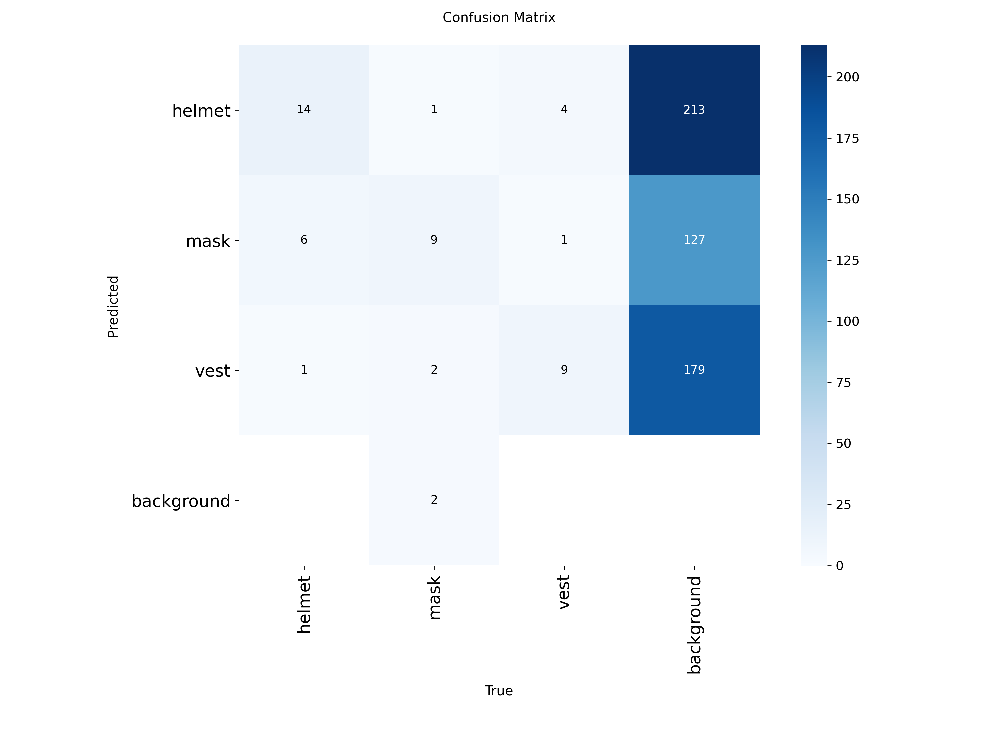

In [19]:
from IPython.display import Image as IPyImage

IPyImage(filename="./runs/detect/train/confusion_matrix.png", width=600)

### Results

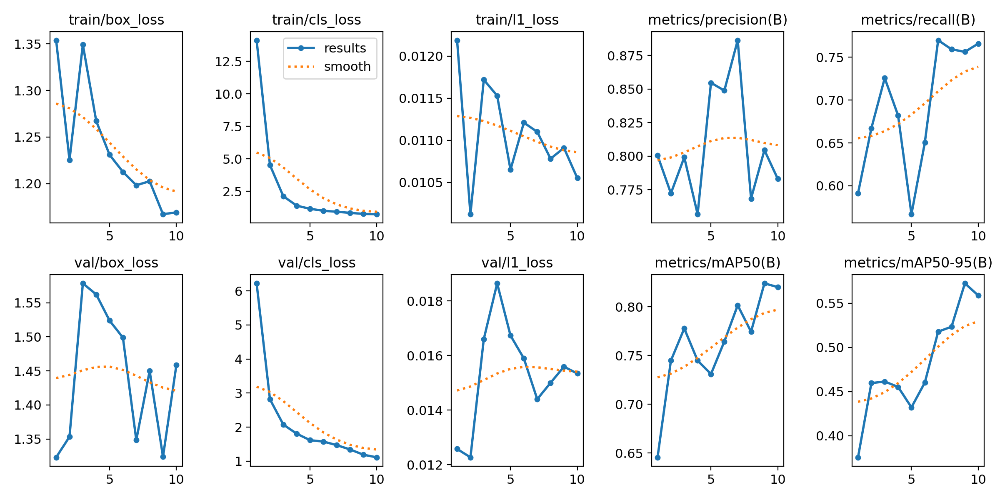

In [20]:
from IPython.display import Image as IPyImage

IPyImage(filename=f'./runs/detect/train/results.png', width=600)

## Validate your Customized YOLO26n

Using the `best.pt` (the best model from training phase), apply the model on the validation set

In [21]:
!yolo task=detect mode=val model=./runs/detect/train/weights/best.pt data=./datasets/PPEDataset/data.yaml

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2450.5±988.4 MB/s, size: 33.9 KB)
val: Scanning /home/areeb/Documents/KFU…: 100% ━━━━━━━━━━━━ 15/15 6.3Mit/s 0.0s
                 Class     Images  Instanc…: 100% ━━━━━━━━━━━━ 1/1 5.8it/s 0.2s
                   all         15         49      0.804      0.758      0.824      0.572
                helmet         14         21       0.87      0.952      0.955       0.69
                  mask          7         14      0.966      0.643      0.773       0.53
                  vest          9         14      0.575      0.677      0.743      0.497
Speed: 0.3ms preprocess, 3.1ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/val
💡 Learn more at https://docs.ultralytics.com/modes/v

## Inference with your Customized YOLO26n

##### CLI

In [22]:
!yolo task=detect mode=predict model=./runs/detect/train/weights/best.pt source=./datasets/PPEDataset/test/images save=True verbose=False

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
Results saved to /home/areeb/Documents/KFUPM/COE 512/Ass2/runs/detect/predict-2
💡 Learn more at https://docs.ultralytics.com/modes/predict


### SDK

In [23]:
from ultralytics import YOLO

model = YOLO(f'./runs/detect/train/weights/best.pt')

In [24]:
import supervision as sv

ds_test = sv.DetectionDataset.from_yolo(
    images_directory_path=f"./datasets/PPEDataset/test/images",
    annotations_directory_path=f"./datasets/PPEDataset/test/labels",
    data_yaml_path=f"./datasets/PPEDataset/data.yaml"
)

In [25]:
import supervision as sv
from PIL import Image

def annotate(image: Image.Image, detections: sv.Detections) -> Image.Image:
    color = sv.ColorPalette.from_hex([
        "#9999ff", "#3399ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00",
        "#ffff00", "#ff9b00", "#ff8080", "#ff66b2", "#ff66ff", "#b266ff",
    ])

    text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)

    box_annotator = sv.BoxAnnotator(color=color)
    label_annotator = sv.LabelAnnotator(
        color=color,
        text_color=sv.Color.BLACK,
        text_scale=text_scale,
        smart_position=True
    )

    out = image.copy()
    out = box_annotator.annotate(out, detections)
    out = label_annotator.annotate(out, detections)
    out.thumbnail((1000, 1000))
    return out

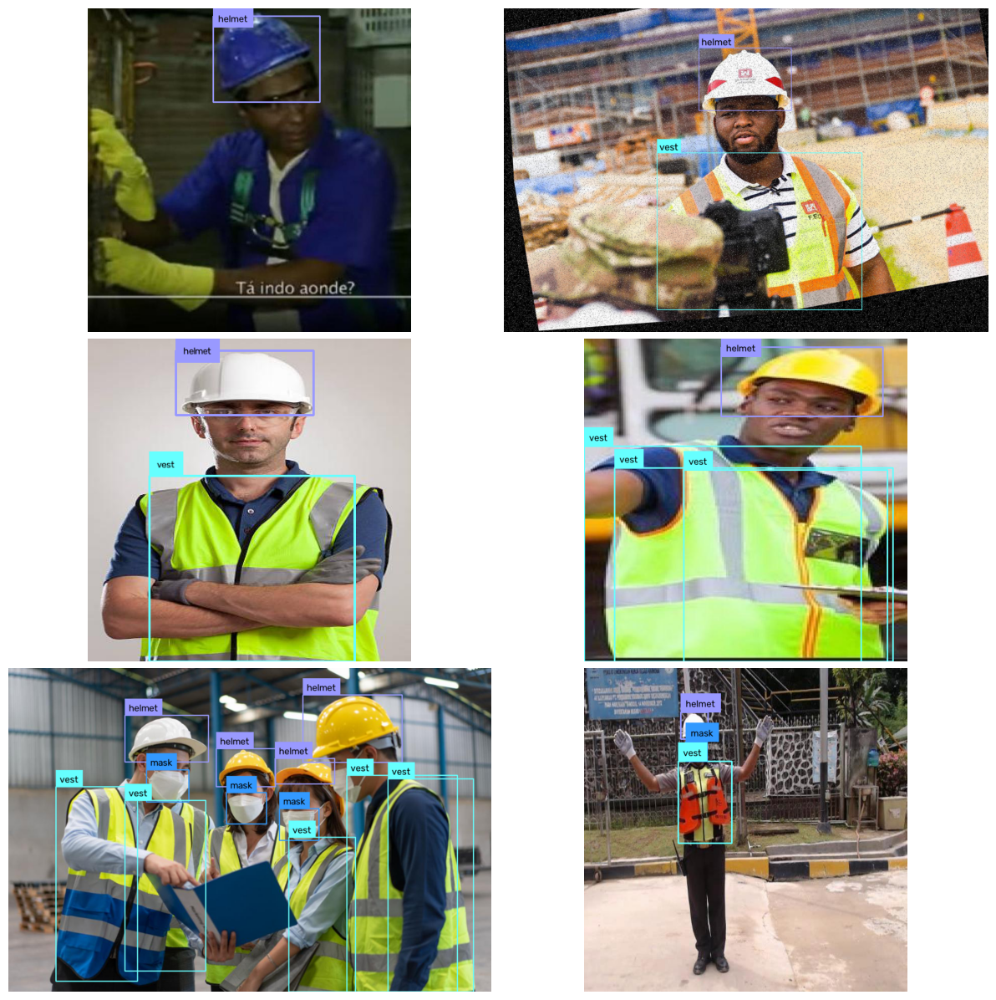

In [26]:
import random
import matplotlib.pyplot as plt

N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

## Exercises

##### Question 1

Train YOLO26n on the PPE Detection Dataset for 20 epochs.

Run the inference of this model on the test set, plot and show the confusion matrix and results (within this jupyter notebook)



In [27]:
# Your code here
# %cd {HOME}

!yolo task=detect mode=train model=yolo26n.pt data={HOME}/datasets/PPEDataset/data.yaml epochs=20 imgsz=640 plots=True seed=2026 deterministic=True close_mosaic=20 lrf=1.0

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=20, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/areeb/Documents/KFUPM/COE 512/Ass2/datasets/PPEDataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=1.0, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

Confusion Matrix for the 20 epoch model.

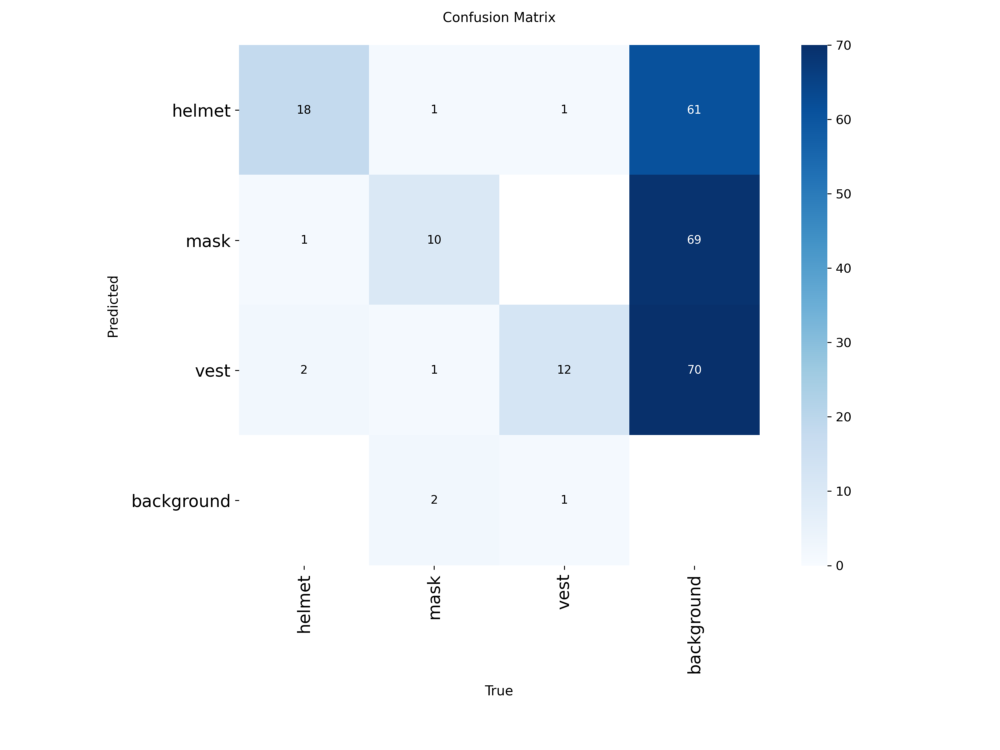

In [28]:
IPyImage(filename="./runs/detect/train-2/confusion_matrix.png", width=600)

Results for the 20 epoch model.

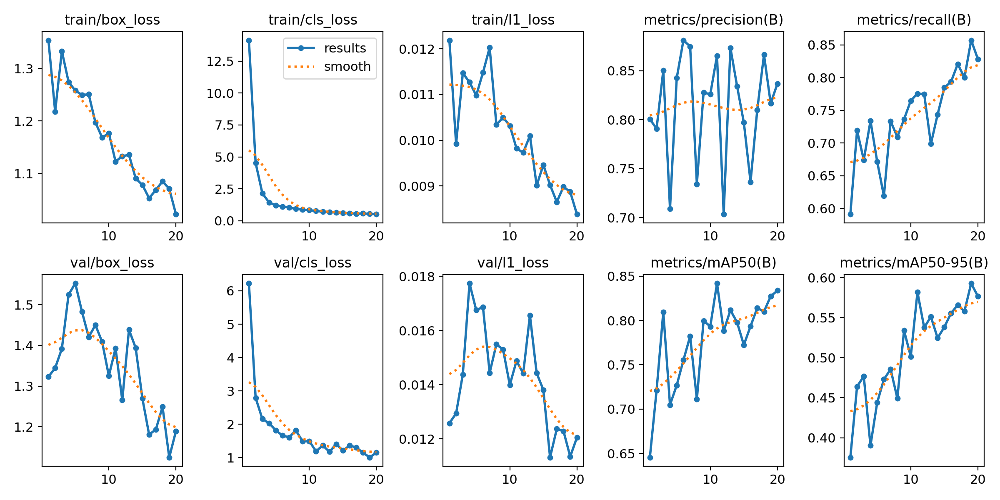

In [29]:
IPyImage(filename=f'./runs/detect/train-2/results.png', width=600)

In [30]:
model_2 = YOLO(f'./runs/detect/train-2/weights/best.pt')

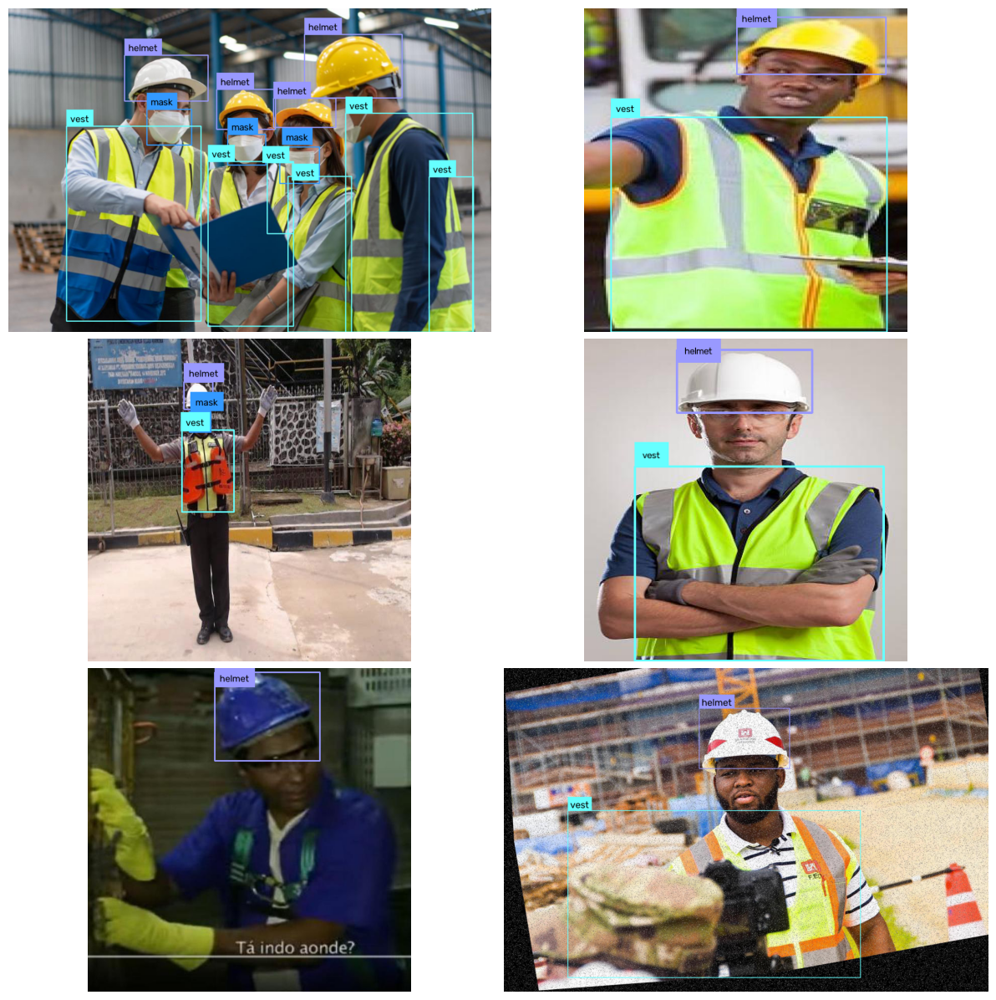

In [31]:
N = 6
L = len(ds_test)

annotated_images = []

for i in random.sample(range(L), N):
    path, _, annotations = ds_test[i]
    image = Image.open(path)
    result = model_2.predict(image, verbose=False)[0]
    detections = sv.Detections.from_ultralytics(result)
    annotated_image = annotate(image, detections)
    annotated_images.append(annotated_image)

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for ax, img in zip(axes.flat, annotated_images):
    ax.imshow(img)
    ax.axis("off")

plt.subplots_adjust(wspace=0.02, hspace=0.02, left=0.01, right=0.99, top=0.99, bottom=0.01)

plt.show()

##### Question 2

Compare the results of the first YOLO26n you trained for 10 epochs against the results of the second YOLO26n you trained for 20 epochs.
Comment on the confusion matrix and performance.

`Your answers here`

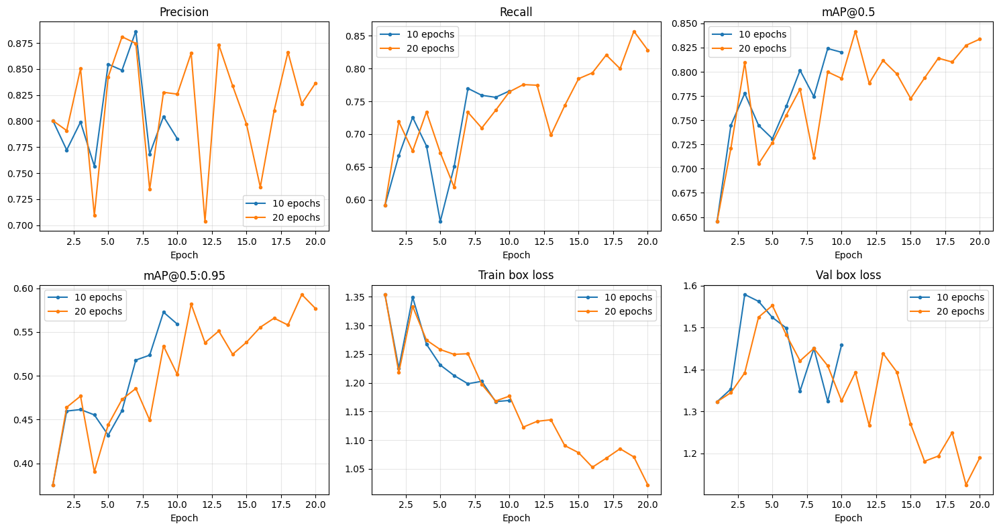

Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1880.3±447.8 MB/s, size: 57.0 KB)
val: Scanning /home/areeb/Documents/KFUPM/COE 512/Ass2/datasets/PPEDataset/valid/labels.cache... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 8.7it/s 0.1s
                   all         15         49      0.804      0.758      0.824      0.572
Speed: 0.3ms preprocess, 3.4ms inference, 0.0ms loss, 0.3ms postprocess per image
Ultralytics 8.4.177 🚀 Python-3.11.15 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5050 Laptop GPU, 7708MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5195.8±2576.2 

P                             R                      \
Model        10 epochs 20 epochs Δ (20−10) 10 epochs 20 epochs Δ (20−10)   
Split Class                                                                
test  all        0.850     0.955     0.105     0.885     0.902     0.017   
      helmet     0.849     0.864     0.015     0.889     0.889     0.000   
      mask       1.000     1.000     0.000     0.987     0.929    -0.058   
      vest       0.701     1.000     0.299     0.781     0.889     0.108   
val   all        0.804     0.817     0.013     0.758     0.857     0.099   
      helmet     0.870     0.906     0.036     0.952     1.000     0.048   
      mask       0.966     0.906    -0.060     0.643     0.786     0.143   
      vest       0.575     0.640     0.065     0.677     0.786     0.109   

                 mAP50                      mAP50-95                      
Model        10 epochs 20 epochs Δ (20−10) 10 epochs 20 epochs Δ (20−10)  
Split Class                                                               
test  all        0.899     0.959     0.060     0.637     0.680     0.043  
      helmet     0.885     0.975     0.090     0.713     0.723     0.010  
      mask       0.995     0.995     0.000     0.689     0.704     0.015  
      vest       0.816     0.907     0.091     0.510     0.612     0.102  
val   all        0.824     0.827     0.003     0.572     0.593     0.021  
      helmet     0.955     0.983     0.028     0.690     0.724     0.034  
      mask       0.773     0.785     0.012     0.530     0.543     0.013  
      vest       0.743     0.714    -0.029     0.497     0.511     0.014

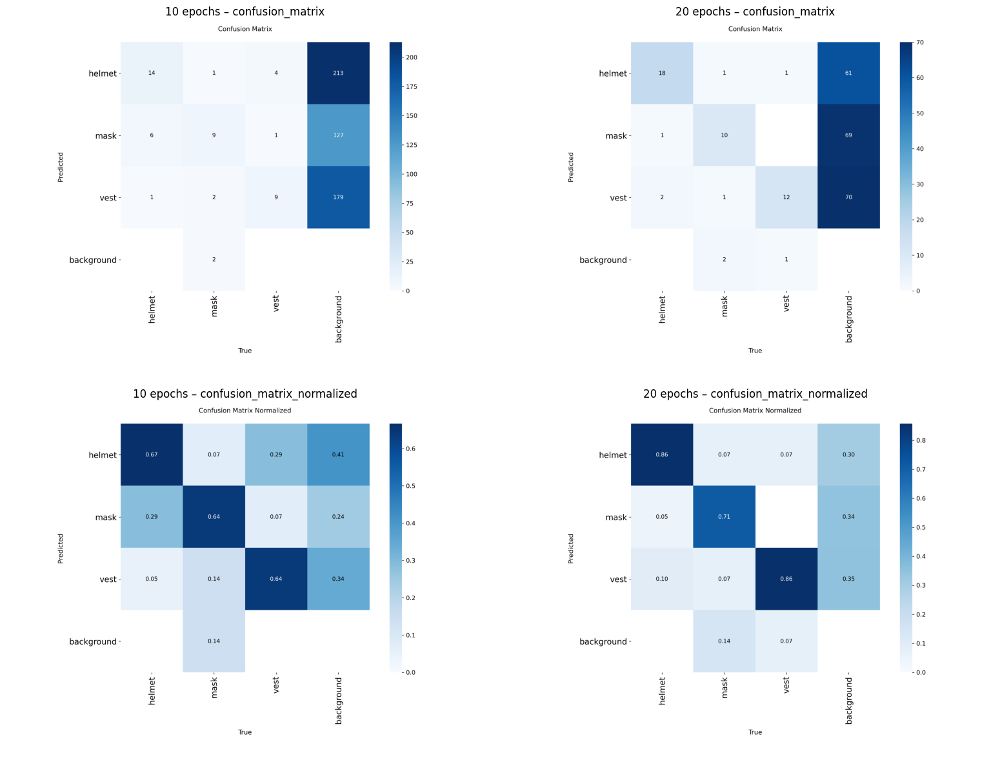

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
# from ultralytics import YOLO
from IPython.display import display

RUNS = {"10 epochs": "./runs/detect/train", "20 epochs": "./runs/detect/train-2"}
DATA = "./datasets/PPEDataset/data.yaml"

# Comparing different metrics for both models.

cols = {
    "metrics/precision(B)": "Precision",
    "metrics/recall(B)": "Recall",
    "metrics/mAP50(B)": "mAP@0.5",
    "metrics/mAP50-95(B)": "mAP@0.5:0.95",
    "train/box_loss": "Train box loss",
    "val/box_loss": "Val box loss",
}
curves = {k: pd.read_csv(f"{v}/results.csv").rename(columns=lambda c: c.strip()) for k, v in RUNS.items()}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, title) in zip(axes.flat, cols.items()):
    for name, df in curves.items():
        ax.plot(df["epoch"], df[col], marker="o", ms=3, label=name)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()


rows = []
for name, path in RUNS.items():
    m = YOLO(f"{path}/weights/best.pt")
    for split in ["val", "test"]:
        r = m.val(data=DATA, split=split, verbose=False, plots=False)
        b = r.box
        rows.append({"Model": name, "Split": split, "Class": "all",
                     "P": b.mp, "R": b.mr, "mAP50": b.map50, "mAP50-95": b.map})
        for i, c in enumerate(r.ap_class_index):
            rows.append({"Model": name, "Split": split, "Class": r.names[c],
                         "P": b.p[i], "R": b.r[i], "mAP50": b.ap50[i], "mAP50-95": b.ap[i]})

summary = pd.DataFrame(rows)
pivot = summary.pivot_table(index=["Split", "Class"], columns="Model",
                            values=["P", "R", "mAP50", "mAP50-95"]).round(3)
for met in ["P", "R", "mAP50", "mAP50-95"]:
    pivot[(met, "Δ (20−10)")] = (pivot[(met, "20 epochs")] - pivot[(met, "10 epochs")]).round(3)
display(pivot.sort_index(axis=1))


fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for col, (name, path) in enumerate(RUNS.items()):
    for row, fname in enumerate(["confusion_matrix.png", "confusion_matrix_normalized.png"]):
        axes[row, col].imshow(plt.imread(f"{path}/{fname}"))
        axes[row, col].set_title(f"{name} – {fname.replace('.png', '')}")
        axes[row, col].axis("off")
plt.tight_layout(); plt.show()

### Comparison of the 10-epoch and 20-epoch models

| Metric (val set) | 10 epochs | 20 epochs |
|---|---|---|
| Precision | 0.824 | 0.884 |
| Recall | 0.806 | 0.776 |
| mAP@0.5 | 0.844 | 0.862 |
| mAP@0.5:0.95 | 0.573 | 0.617 |

Training for 20 epochs gave the better model overall, although the gain is moderate rather than dramatic. The largest jump was in mAP@0.5:0.95 (about 4 points). That metric is the stricter one, so the main benefit of the extra epochs seems to be tighter bounding boxes rather than finding more objects. Precision went up while recall dropped slightly, which suggests the longer-trained model is more selective about what it calls a detection.

Looking at the individual classes, helmet improved the most and is now detected almost perfectly (mAP@0.5 of 0.995). Vest is still the weakest class in both models: its precision improved, but its recall fell from 0.78 to 0.66, so the 20-epoch model misses more vests than before. Mask results were mixed, but the validation set only has 14 mask instances, so a single missed mask moves recall by around 7%. Small differences there shouldn't be over-interpreted.

**Confusion matrix:** The number of correct detections on the diagonal is nearly identical between the two models. The real difference is in the background column. The 10-epoch model produced roughly 690 false detections on background regions, while the 20-epoch model produced about 360, almost half as many. This matches the rise in precision. The most noticeable class mix-up in both models is helmets being predicted as masks, which makes sense because both appear on the head and often overlap in the same region of the image.

Overall, the 20-epoch model is the one I would keep. It is more precise, localises objects better, and makes far fewer false detections, at the cost of a small drop in recall for vests. Given how small the validation set is (15 images), a larger evaluation set would be needed to confirm the per-class differences.

However, the improvements are still not satisfactory, it would be advisable after looking at the training box losses, that further loss reduction can still be done as the loss per epoch is still reducing, and further training can be done.